In [20]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


In [21]:
df = pd.read_csv('/content/edu.csv')
df.head()

,country,date,GNP,Population,Edu_prime,Edu_second,Edu_post_second,Edu_lower_second,Unemp,c_codes
0,ARAB WORLD,2017,16997.503539,414491886.0,NaN,NaN,NaN,NaN,NaN,NaN
1,ARAB WORLD,2016,16794.064949,406452690.0,83.911949,NaN,NaN,NaN,NaN,NaN
2,ARAB WORLD,2015,16366.596405,398304960.0,84.720306,NaN,NaN,NaN,NaN,NaN
3,ARAB WORLD,2014,15895.251480,390043028.0,85.314812,NaN,NaN,NaN,NaN,NaN
4,ARAB WORLD,2013,15453.220686,381702086.0,84.703484,NaN,NaN,NaN,NaN,NaN


In [22]:
df.tail()

,country,date,GNP,Population,Edu_prime,Edu_second,Edu_post_second,Edu_lower_second,Unemp,c_codes
15307,ZIMBABWE,1964,NaN,4269863.0,NaN,NaN,NaN,NaN,NaN,ZWE
15308,ZIMBABWE,1963,NaN,4132756.0,NaN,NaN,NaN,NaN,NaN,ZWE
15309,ZIMBABWE,1962,NaN,3999419.0,NaN,NaN,NaN,NaN,NaN,ZWE
15310,ZIMBABWE,1961,NaN,3870756.0,NaN,NaN,NaN,NaN,NaN,ZWE
15311,ZIMBABWE,1960,NaN,3747369.0,NaN,NaN,NaN,NaN,NaN,ZWE


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15312 entries, 0 to 15311
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   country           15312 non-null  object 
 1   date              15312 non-null  int64  
 2   GNP               6277 non-null   float64
 3   Population        15147 non-null  float64
 4   Edu_prime         6441 non-null   float64
 5   Edu_second        870 non-null    float64
 6   Edu_post_second   790 non-null    float64
 7   Edu_lower_second  976 non-null    float64
 8   Unemp             1692 non-null   float64
 9   c_codes           10556 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 1.2+ MB


In [24]:
df.shape

(15312, 10)

In [25]:
df.columns

Index(['country', 'date', 'GNP', 'Population', 'Edu_prime', 'Edu_second',
       'Edu_post_second', 'Edu_lower_second', 'Unemp', 'c_codes'],
      dtype='object')

In [26]:
df.isnull().sum()

,0
country,0
date,0
GNP,9035
Population,165
Edu_prime,8871
Edu_second,14442
Edu_post_second,14522
Edu_lower_second,14336
Unemp,13620
c_codes,4756


In [27]:
df['country'].nunique()

264

In [28]:
df['country'].unique()

array(['ARAB WORLD', 'CARIBBEAN SMALL STATES',
       'CENTRAL EUROPE AND THE BALTICS', 'EARLY-DEMOGRAPHIC DIVIDEND',
       'EAST ASIA & PACIFIC',
       'EAST ASIA & PACIFIC (EXCLUDING HIGH INCOME)',
       'EAST ASIA & PACIFIC (IDA & IBRD COUNTRIES)', 'EURO AREA',
       'EUROPE & CENTRAL ASIA',
       'EUROPE & CENTRAL ASIA (EXCLUDING HIGH INCOME)',
       'EUROPE & CENTRAL ASIA (IDA & IBRD COUNTRIES)', 'EUROPEAN UNION',
       'FRAGILE AND CONFLICT AFFECTED SITUATIONS',
       'HEAVILY INDEBTED POOR COUNTRIES (HIPC)', 'HIGH INCOME',
       'IBRD ONLY', 'IDA & IBRD TOTAL', 'IDA BLEND', 'IDA ONLY',
       'IDA TOTAL', 'LATE-DEMOGRAPHIC DIVIDEND',
       'LATIN AMERICA & CARIBBEAN',
       'LATIN AMERICA & CARIBBEAN (EXCLUDING HIGH INCOME)',
       'LATIN AMERICA & THE CARIBBEAN (IDA & IBRD COUNTRIES)',
       'LEAST DEVELOPED COUNTRIES: UN CLASSIFICATION',
       'LOW & MIDDLE INCOME', 'LOW INCOME', 'LOWER MIDDLE INCOME',
       'MIDDLE EAST & NORTH AFRICA',
       'MIDDLE EAST & NO

In [29]:
df['date'].nunique()

58

In [30]:
df['date'].unique()

array([2017, 2016, 2015, 2014, 2013, 2012, 2011, 2010, 2009, 2008, 2007,
       2006, 2005, 2004, 2003, 2002, 2001, 2000, 1999, 1998, 1997, 1996,
       1995, 1994, 1993, 1992, 1991, 1990, 1989, 1988, 1987, 1986, 1985,
       1984, 1983, 1982, 1981, 1980, 1979, 1978, 1977, 1976, 1975, 1974,
       1973, 1972, 1971, 1970, 1969, 1968, 1967, 1966, 1965, 1964, 1963,
       1962, 1961, 1960])

In [31]:
df['GNP'].nunique()

3627

In [32]:
df['GNP'].unique()

array([16997.50353864, 16794.06494864, 16366.59640458, ...,
        4180.        ,  3530.        ,  3800.        ], shape=(3628,))

In [33]:
df['Population'].nunique()

14958

In [34]:
df['Population'].unique()

array([4.14491886e+08, 4.06452690e+08, 3.98304960e+08, ...,
       3.99941900e+06, 3.87075600e+06, 3.74736900e+06], shape=(14959,))

In [35]:
df['Edu_prime'].nunique()

6343

In [36]:
df['Edu_prime'].unique()

array([        nan, 83.91194916, 84.7203064 , ..., 92.6124115 ,
       93.33759308, 85.43900299], shape=(6344,))

In [37]:
df['Edu_second'].nunique()

869

In [38]:
df['Edu_second'].unique()

array([        nan,  3.        , 45.2791481 , 43.49034119, 39.88911057,
       37.04489136, 25.41651917,  7.65761995, 47.54520035, 47.83740997,
       42.15663147, 34.29335022, 91.83743286, 90.23760986, 81.58307648,
       32.11751938, 75.55976105, 71.23394012, 72.03684235, 76.48301697,
       74.0616684 , 72.79897308, 70.85574341, 70.08895874, 68.18978119,
       66.71383667, 65.03385162, 64.1210022 , 79.01290131, 78.10984039,
       77.30635834, 76.97511292, 76.42769623, 76.55609894, 75.81018829,
       72.46945953, 73.59060669, 74.2021637 , 50.7143898 , 38.32165146,
       88.66507721, 88.71417236, 88.71620941, 88.71308899, 88.65878296,
       88.645401  , 88.61048889, 82.96022034, 82.94914246, 83.52632141,
       81.87773132, 70.94155121, 42.11301041, 49.65031052, 17.12842941,
        5.49604988, 24.20573044, 84.85410309, 66.21057892, 64.01886749,
       64.27867889, 63.21110153, 62.75992966, 61.7283783 , 61.69290161,
       60.42416   , 57.73292923, 14.01618958, 36.82701874,  1.10

In [39]:
df['Edu_post_second'].nunique()

770

In [40]:
df['Edu_post_second'].unique()

array([        nan,  3.02445006,  1.70000994, 12.89966011, 12.00263023,
        9.81624031,  7.42787981,  0.31726   , 32.42024994, 32.68107986,
       30.47790909, 28.10639   , 30.51041985, 12.00990963,  6.0999999 ,
        4.        , 50.56063843, 46.9643898 , 42.11391068,  7.18651009,
       45.34506989, 39.03498077, 41.6409111 , 46.46197128, 42.70265961,
       41.79571152, 40.55582809, 39.35686874, 36.73524094, 35.72978973,
       34.20449066, 33.36499023, 21.5       , 29.14282036, 28.41851997,
       27.82756042, 26.99064064, 26.33883095, 26.16739082, 25.62254906,
       23.59576035, 23.86700058, 23.83703041,  6.10451984,  3.24651003,
        2.55789995, 30.04166031, 30.05711937, 30.03313065, 30.03635025,
       30.00222015, 29.96822929, 29.82192039, 33.35760117, 33.29056931,
       32.59635925, 31.25805092, 19.17625046, 13.46815014, 40.11994934,
       10.30000019,  3.79999995,  4.20865011,  1.27348006,  0.86032999,
       15.68185043,  3.35552001,  1.20000005, 63.3762207 , 12.51

In [41]:
df['Edu_lower_second'].nunique()

963

In [42]:
df['Edu_lower_second'].unique()

array([         nan,   4.14899015,   4.09997988,  87.21489716,
        85.22621918,  81.73378754,  75.73404694,  47.30498886,
        24.15286064,   2.52578998,  72.50061035,  72.84458923,
        49.95064926,  43.91017151,  51.45418167,  42.30387115,
        56.37567902,  45.8916893 ,  37.35631943,  26.5       ,
        19.29999924,  97.22245789,  96.59977722,  91.07919312,
        60.79969025,  55.99243164,  46.09238052,  92.67857361,
        91.45050049,  91.0807724 ,  94.44893646,  93.60810089,
        93.19953156,  92.23867035,  92.33435059,  91.72463989,
        91.14067078,  90.85430145,  89.73760223,  69.80000305,
        98.92321777,  95.60848999,  95.6078186 ,  95.59149933,
        95.56986237,  95.55583954,  95.56773376,  95.46668243,
        92.71167755,  92.67681885,  92.837883  ,  89.13713074,
        90.10501862,  71.14201355,  54.89627075,  68.33722687,
        35.40000153,  13.        ,  26.71472931,  12.86266041,
         7.6950798 ,  78.10392761,  66.80323792,  65.30

In [43]:
df['Unemp'].nunique()

1610

In [44]:
df['Unemp'].unique()

array([        nan,  3.11453689,  3.93357841, ..., 31.92350006,
       33.22999954,  9.42310047], shape=(1611,))

In [64]:
df['c_codes'].nunique()

183

In [65]:
df['c_codes'].unique()

array(['unknown', 'AFG', 'ALB', 'DZA', 'ASM', 'AND', 'AGO', 'ATG', 'ARG',
       'ARM', 'ABW', 'AUS', 'AUT', 'AZE', 'BHR', 'BGD', 'BRB', 'BLR',
       'BEL', 'BLZ', 'BEN', 'BMU', 'BTN', 'BIH', 'BWA', 'BRA', 'BRN',
       'BGR', 'BFA', 'BDI', 'KHM', 'CMR', 'CAN', 'KYM', 'CAF', 'TCD',
       'CHL', 'CHN', 'COL', 'COM', 'CRI', 'HRV', 'CUB', 'CYP', 'CZE',
       'DNK', 'DJI', 'DMA', 'DOM', 'ECU', 'SLV', 'GNQ', 'ERI', 'EST',
       'ETH', 'FRO', 'FJI', 'FIN', 'FRA', 'PYF', 'GAB', 'GEO', 'DEU',
       'GHA', 'GIB', 'GRC', 'GRL', 'GRD', 'GUM', 'GTM', 'GIN', 'GNB',
       'GUY', 'HTI', 'HND', 'HUN', 'ISL', 'IND', 'IDN', 'IRQ', 'IRL',
       'IMN', 'ISR', 'ITA', 'JAM', 'JPN', 'JOR', 'KAZ', 'KEN', 'KIR',
       'KWT', 'LVA', 'LBN', 'LSO', 'LRR', 'LIE', 'LTU', 'LUX', 'MDG',
       'MWI', 'MYS', 'MDV', 'MLI', 'MLT', 'MHL', 'MRT', 'MUS', 'MEX',
       'MCO', 'MNG', 'MNE', 'MAR', 'MOZ', 'MMR', 'NAM', 'NRU', 'NPL',
       'NLD', 'NCL', 'NZL', 'NIC', 'NER', 'NGA', 'MNP', 'NOR', 'OMN',
       'PAK', 'P

In [45]:
df.isnull().sum()

,0
country,0
date,0
GNP,9035
Population,165
Edu_prime,8871
Edu_second,14442
Edu_post_second,14522
Edu_lower_second,14336
Unemp,13620
c_codes,4756


# Null value replacing

In [46]:
df['GNP'].fillna(df['GNP'].mean(),inplace=True)

/tmp/ipykernel_359/3307600198.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['GNP'].fillna(df['GNP'].mean(),inplace=True)


In [47]:
df['Population'].fillna(df['Population'].mean(),inplace=True)

/tmp/ipykernel_359/491426745.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Population'].fillna(df['Population'].mean(),inplace=True)


In [48]:
df['Edu_prime'].fillna(df['Edu_prime'].mean(),inplace=True)

/tmp/ipykernel_359/1267002673.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Edu_prime'].fillna(df['Edu_prime'].mean(),inplace=True)


In [49]:
df['Edu_second'].fillna(df['Edu_second'].mean(),inplace=True)

/tmp/ipykernel_359/3017867957.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Edu_second'].fillna(df['Edu_second'].mean(),inplace=True)


In [50]:
df['Edu_post_second'].fillna(df['Edu_post_second'].mean(),inplace=True)

/tmp/ipykernel_359/1761685254.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Edu_post_second'].fillna(df['Edu_post_second'].mean(),inplace=True)


In [51]:
df['Edu_lower_second'].fillna(df['Edu_lower_second'].mean(),inplace=True)

/tmp/ipykernel_359/235609917.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Edu_lower_second'].fillna(df['Edu_lower_second'].mean(),inplace=True)


In [52]:
df.isnull().sum()

,0
country,0
date,0
GNP,0
Population,0
Edu_prime,0
Edu_second,0
Edu_post_second,0
Edu_lower_second,0
Unemp,13620
c_codes,4756


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15312 entries, 0 to 15311
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   country           15312 non-null  object 
 1   date              15312 non-null  int64  
 2   GNP               15312 non-null  float64
 3   Population        15312 non-null  float64
 4   Edu_prime         15312 non-null  float64
 5   Edu_second        15312 non-null  float64
 6   Edu_post_second   15312 non-null  float64
 7   Edu_lower_second  15312 non-null  float64
 8   Unemp             1692 non-null   float64
 9   c_codes           10556 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 1.2+ MB


In [54]:
df['c_codes'].fillna('unknown',inplace=True)

/tmp/ipykernel_359/2434414656.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['c_codes'].fillna('unknown',inplace=True)


In [55]:
df['Unemp'].fillna(df['Unemp'].mean(),inplace=True)

/tmp/ipykernel_359/2127480604.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Unemp'].fillna(df['Unemp'].mean(),inplace=True)


In [56]:
df.isnull().sum()

,0
country,0
date,0
GNP,0
Population,0
Edu_prime,0
Edu_second,0
Edu_post_second,0
Edu_lower_second,0
Unemp,0
c_codes,0


In [57]:
df.head()

,country,date,GNP,Population,Edu_prime,Edu_second,Edu_post_second,Edu_lower_second,Unemp,c_codes
0,ARAB WORLD,2017,16997.503539,414491886.0,78.546217,49.265608,18.708057,58.146177,7.285639,unknown
1,ARAB WORLD,2016,16794.064949,406452690.0,83.911949,49.265608,18.708057,58.146177,7.285639,unknown
2,ARAB WORLD,2015,16366.596405,398304960.0,84.720306,49.265608,18.708057,58.146177,7.285639,unknown
3,ARAB WORLD,2014,15895.251480,390043028.0,85.314812,49.265608,18.708057,58.146177,7.285639,unknown
4,ARAB WORLD,2013,15453.220686,381702086.0,84.703484,49.265608,18.708057,58.146177,7.285639,unknown


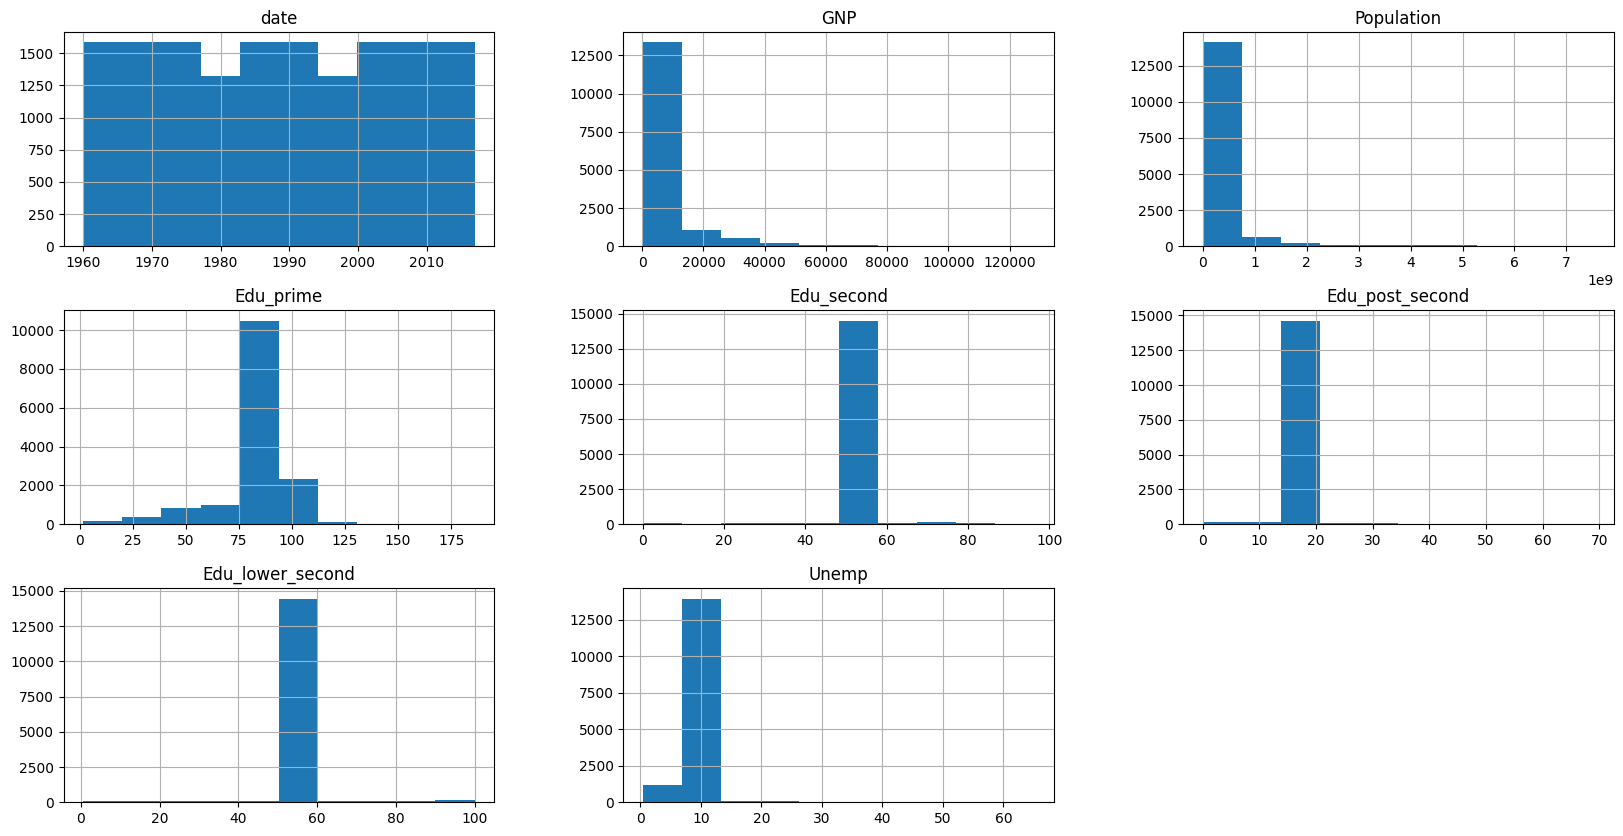

In [58]:
df.hist(figsize=(20,10))
plt.show()

In [59]:
df.sample(3)

,country,date,GNP,Population,Edu_prime,Edu_second,Edu_post_second,Edu_lower_second,Unemp,c_codes
4179,BOTSWANA,2014,16410.000000,2168573.0,69.183640,49.265608,18.708057,58.146177,7.285639,BWA
13609,SWEDEN,1980,12491.472098,8310531.0,103.192207,49.265608,18.708057,58.146177,7.285639,SWE
6770,FRENCH POLYNESIA,1975,12491.472098,130619.0,78.546217,49.265608,18.708057,58.146177,7.285639,PYF


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15312 entries, 0 to 15311
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   country           15312 non-null  object 
 1   date              15312 non-null  int64  
 2   GNP               15312 non-null  float64
 3   Population        15312 non-null  float64
 4   Edu_prime         15312 non-null  float64
 5   Edu_second        15312 non-null  float64
 6   Edu_post_second   15312 non-null  float64
 7   Edu_lower_second  15312 non-null  float64
 8   Unemp             15312 non-null  float64
 9   c_codes           15312 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 1.2+ MB


In [61]:
df.describe()

,date,GNP,Population,Edu_prime,Edu_second,Edu_post_second,Edu_lower_second,Unemp
count,15312.000000,15312.000000,1.531200e+04,15312.000000,15312.000000,15312.000000,15312.000000,15312.000000
mean,1988.500000,12491.472098,2.060462e+08,78.546217,49.265608,18.708057,58.146177,7.285639
std,16.741216,9786.241434,6.756365e+08,15.813735,6.163528,3.131133,7.305072,2.332995
min,1960.000000,230.000000,4.279000e+03,1.521950,0.000000,0.000000,0.600000,0.440000
25%,1974.000000,9820.000000,9.698788e+05,78.546217,49.265608,18.708057,58.146177,7.285639
50%,1988.500000,12491.472098,6.605686e+06,78.546217,49.265608,18.708057,58.146177,7.285639
75%,2003.000000,12491.472098,4.701263e+07,79.511600,49.265608,18.708057,58.146177,7.285639
max,2017.000000,128060.000000,7.530360e+09,186.054626,96.308228,69.071663,100.000000,65.089996


In [62]:
df.head()

,country,date,GNP,Population,Edu_prime,Edu_second,Edu_post_second,Edu_lower_second,Unemp,c_codes
0,ARAB WORLD,2017,16997.503539,414491886.0,78.546217,49.265608,18.708057,58.146177,7.285639,unknown
1,ARAB WORLD,2016,16794.064949,406452690.0,83.911949,49.265608,18.708057,58.146177,7.285639,unknown
2,ARAB WORLD,2015,16366.596405,398304960.0,84.720306,49.265608,18.708057,58.146177,7.285639,unknown
3,ARAB WORLD,2014,15895.251480,390043028.0,85.314812,49.265608,18.708057,58.146177,7.285639,unknown
4,ARAB WORLD,2013,15453.220686,381702086.0,84.703484,49.265608,18.708057,58.146177,7.285639,unknown


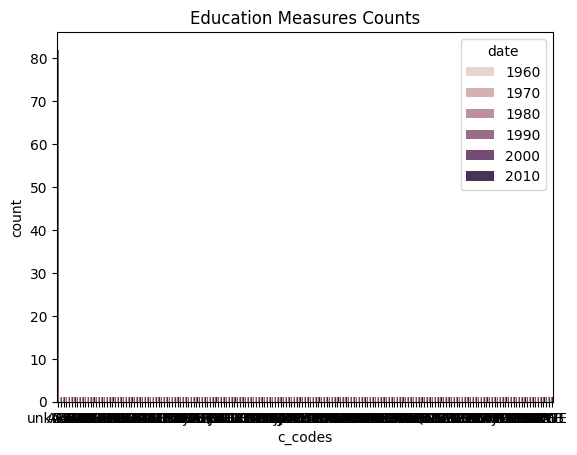

In [76]:
sns.countplot(x='c_codes' , hue='date',data=df)
plt.title('Education Measures Counts')
plt.show()

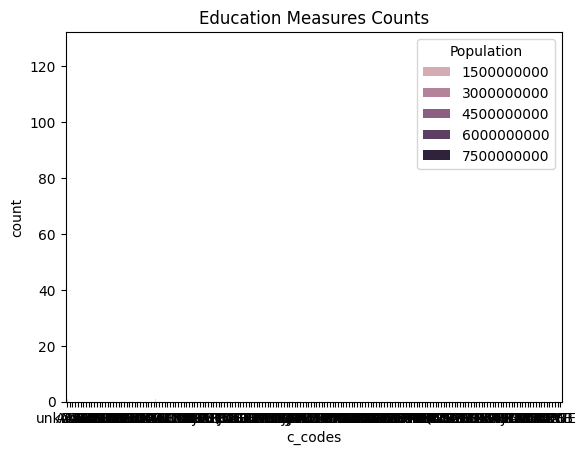

In [84]:
sns.countplot(x='c_codes' , hue='Population',data=df)
plt.title('Education Measures Counts')
plt.show()

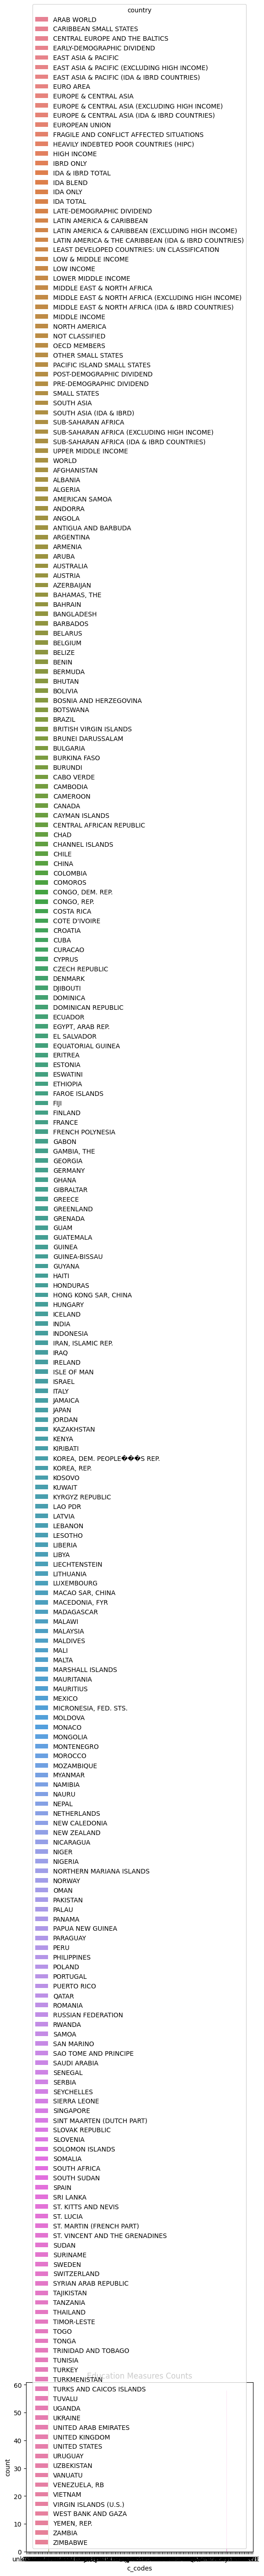

In [85]:
sns.countplot(x='c_codes' , hue='country',data=df)
plt.title('Education Measures Counts')
plt.show()

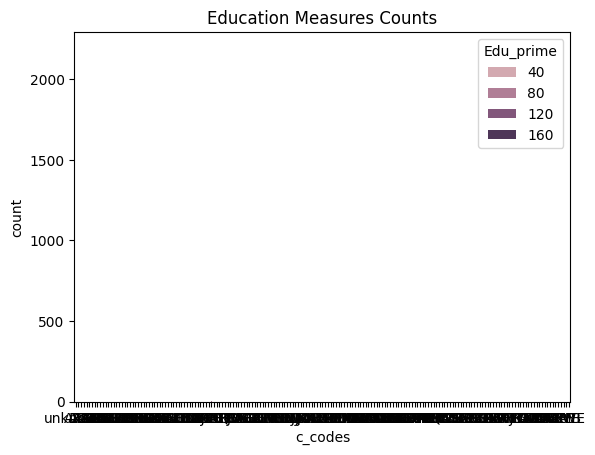

In [86]:
sns.countplot(x='c_codes' , hue='Edu_prime',data=df)
plt.title('Education Measures Counts')
plt.show()

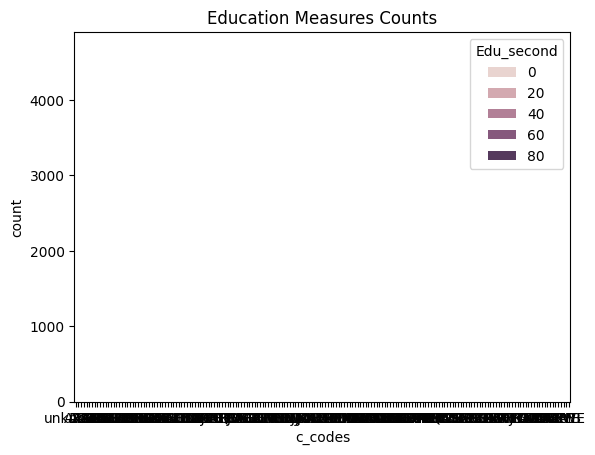

In [87]:
sns.countplot(x='c_codes' , hue='Edu_second',data=df)
plt.title('Education Measures Counts')
plt.show()